# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [80]:
ПІБ = 'Лящук Соломія'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-33'      # напр. 'КН-31'
ВАРІАНТ = 6     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [81]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 6 · Лящук Соломія, ШІ-33, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            3    2        1       4    630
Столярний цех, год         4    2        2       1    391
Фарбувальний цех, год      3    5        1       2   1349
Такелаж, компл.            3    2        0       2    811
Ділянка добудови, год      6    4        6       3   1085

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     40   62       19      57

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Столярний цех, год
  ціна:   29.5 за одиницю
  обсяг:  до 268 одиниць


In [82]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x = (x1, x2, x3, x4)

Цільова функція: F = 40·x1 + 62·x2 + 19·x3 + 57·x4 → max

Обмеження: 3·x1 + 2·x2 + 1·x3 + 4·x4 ≤ 630    (склопластик, м²)
4·x1 + 2·x2 + 2·x3 + 1·x4 ≤ 391    (столярний цех, год)
3·x1 + 5·x2 + 1·x3 + 2·x4 ≤ 1349   (фарбувальний цех, год)
3·x1 + 2·x2 + 0·x3 + 2·x4 ≤ 811    (такелаж, компл.)
6·x1 + 4·x2 + 6·x3 + 3·x4 ≤ 1085   (ділянка добудови, год)

Невід'ємність: x1, x2, x3, x4 ≥ 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2: Запас це параметр, бо він заданий ззовні (стільки ресурсу є на місяць), а фірма вирішує лише, скільки яхт випустити. Якби ресурс можна було докупити в будь-якій кількості, його обсяг став би ще однією змінною рішення, а в цільовій функції з'явилася б вартість закупівлі.**

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом. 

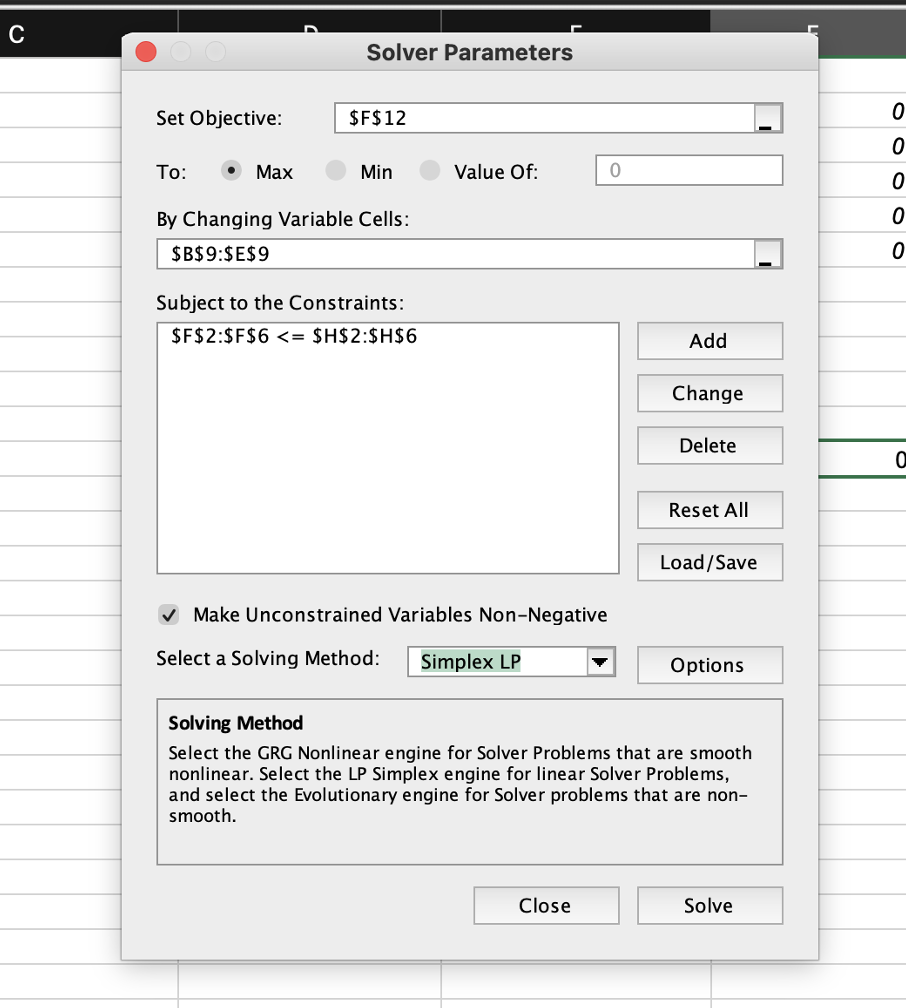 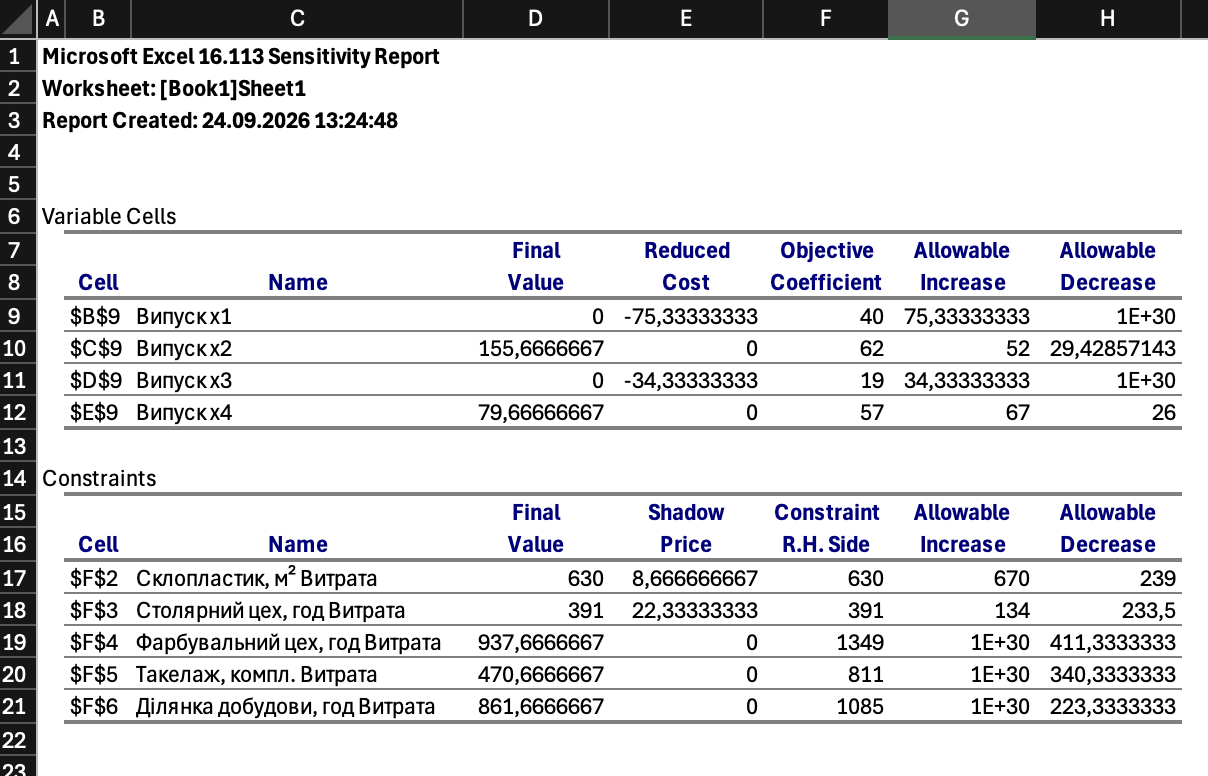 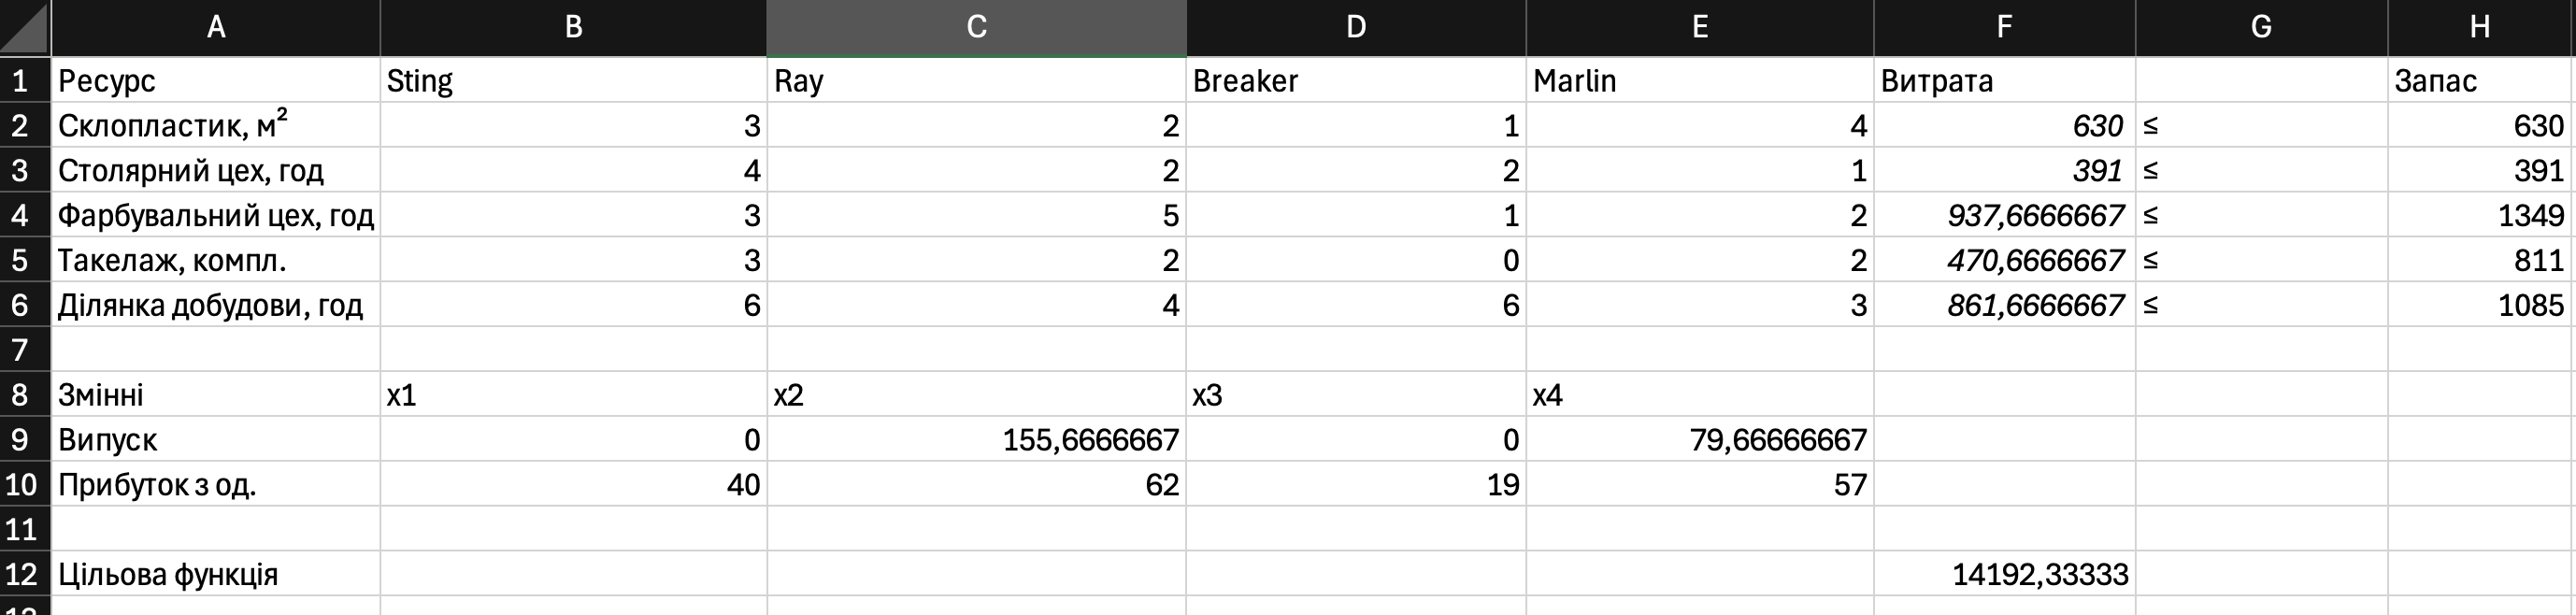
### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [83]:
EXCEL_ПЛАН     = [0, 155.6666667, 0, 79.66666667]
EXCEL_ПРИБУТОК = 14192.33333

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 155.6666667, 0, 79.66666667] | прибуток 14192.33333


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [84]:
r = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c), method='highs')
assert r.success, r.message

план = r.x
прибуток = -r.fun

for назва, x in zip(вироби, план):
    print('%-8s %.4f' % (назва, x))
print('Прибуток: %.4f' % прибуток)

Sting    0.0000
Ray      155.6667
Breaker  0.0000
Marlin   79.6667
Прибуток: 14192.3333


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [85]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Склопластик | 630 | 8,67 | 630 | 670 | 239 |
| Столярний цех | 391 | 22,33 | 391 | 134 | 233,5 |
| Фарбувальний цех | 937,67 | 0 | 1349 | 1E+30 | 411,33 |
| Такелаж | 470,67 | 0 | 811 | 1E+30 | 340,33 |
| Ділянка добудови | 861,67 | 0 | 1085 | 1E+30 | 223,33 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

У дефіциті склопластик і столярний цех: їх витрачено повністю (кінцеве значення дорівнює правій частині), а тіньова ціна додатна (8,67 і 22,33). Саме вони обмежують випуск. У надлишку фарбувальний цех, такелаж і ділянка добудови: витрачено менше за запас (лишається 411,33, 340,33 і 223,33), тіньова ціна нульова, тож додатковий запас цих ресурсів прибутку не дасть.


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Sting | 0 | −75,33 | 40 | 75,33 | 1E+30 |
| Ray | 155,67 | 0 | 62 | 52 | 29,43 |
| Breaker | 0 | −34,33 | 19 | 34,33 | 1E+30 |
| Marlin | 79,67 | 0 | 57 | 67 | 26 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Не виробляються Sting і Breaker. Щоб Breaker увійшов у план, прибуток з його одиниці має зрости щонайменше на 34,33 (з 19 до 53,33). Для Sting потрібно зростання на 75,33 (з 40 до 115,33). Числа взяті зі стовпця «Зведена вартість» у звіті Excel (за модулем; мінус означає, що випуск цього виробу зменшив би загальний прибуток). 


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [86]:
def розв(запаси):
    r = linprog(-c, A_ub=A, b_ub=запаси, bounds=[(0, None)] * len(c), method='highs')
    assert r.success, r.message
    return r

база = розв(b)
тіньові = -база.ineqlin.marginals     
i = int(np.argmax(тіньові))           

b2 = b.copy()
b2[i] += 1                            
нов = розв(b2)

print('Ресурс:', ресурси[i])
print('Приріст прибутку: %.4f' % (-нов.fun - (-база.fun)))
print('Тіньова ціна:     %.4f' % тіньові[i])


Ресурс: Столярний цех, год
Приріст прибутку: 22.3333
Тіньова ціна:     22.3333


**Відповідь 5.1:Найдорожчий ресурс: столярний цех. Приріст прибутку при +1 год дорівнює 22,33, тіньова ціна зі звіту 22,33. Збігаються, тож звіт Excel підтверджено експериментом.** 


### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

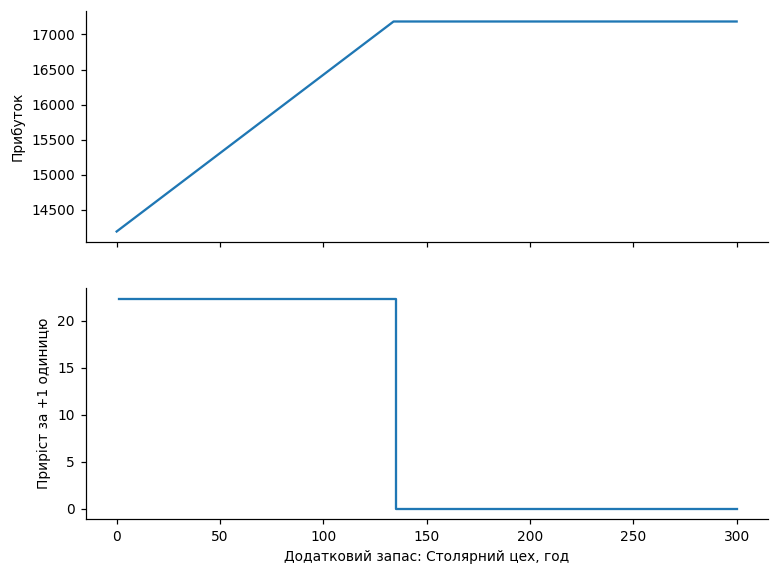

Тіньова ціна діє до +134 одиниць


In [87]:
кроки = np.arange(0, 301)             
прибутки = []
for k in кроки:
    bb = b.copy()
    bb[i] = b[i] + k
    прибутки.append(-розв(bb).fun)
прибутки = np.array(прибутки)
нахил = np.diff(прибутки)             

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
ax1.plot(кроки, прибутки)
ax1.set_ylabel('Прибуток')
ax2.step(кроки[1:], нахил, where='post')
ax2.set_ylabel('Приріст за +1 одиницю')
ax2.set_xlabel('Додатковий запас: %s' % ресурси[i])
plt.show()

межа = int(np.argmax(np.abs(нахил - нахил[0]) > 1e-6))  
print('Тіньова ціна діє до +%d одиниць' % межа)

**Відповідь 5.2:Тіньова ціна 22,33 діє, поки запас столярного цеху збільшується не більше ніж на 134 год. Далі приріст прибутку падає до нуля, бо цех перестає бути обмежувальним, і план обмежують інші ресурси. Межа 134 збігається з «допустимим збільшенням» зі звіту Excel.** 

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [88]:
ціна = V['ціна_пропозиції']
обсяг = V['обсяг_пропозиції']
j = V['ресурс_пропозиції']    

print('Ресурс: %s' % ресурси[j])
print('Ціна пропозиції: %.2f | тіньова ціна: %.2f' % (ціна, тіньові[j]))
print('Брати вигідно?', ціна < тіньові[j])

базовий_прибуток = -база.fun
for k in [0, 50, 100, межа, обсяг]:   
    bb = b.copy()
    bb[j] += k
    п = -розв(bb).fun
    print('k=%3d | прибуток %.2f | витрати %.2f | чистий результат %+.2f'
          % (k, п, ціна * k, п - ціна * k - базовий_прибуток))

Ресурс: Столярний цех, год
Ціна пропозиції: 29.50 | тіньова ціна: 22.33
Брати вигідно? False
k=  0 | прибуток 14192.33 | витрати 0.00 | чистий результат +0.00
k= 50 | прибуток 15309.00 | витрати 1475.00 | чистий результат -358.33
k=100 | прибуток 16425.67 | витрати 2950.00 | чистий результат -716.67
k=134 | прибуток 17185.00 | витрати 3953.00 | чистий результат -960.33
k=268 | прибуток 17185.00 | витрати 7906.00 | чистий результат -4913.33


**Відповідь 6.1:**
* Брати чи ні і чому: Ні. Ціна пропозиції (29,5) вища за тіньову ціну столярного цеху (22,33): кожна купована година дає 22,33 прибутку, а коштує 29,5, тобто збиток 7,17 за одиницю.
* Скільки одиниць має сенс купити і чому не більше: У цьому варіанті жодної. Але якби ціна була нижчою за 22,33, купувати можна було б не більше 134 год: це межа діапазону з етапу 5.2, далі тіньова ціна падає до нуля, і додаткові години вже не збільшують прибуток, а лише коштують грошей. Пропозиція на 268 год більша за потрібне.
* Очікуваний виграш: Купівля виграшу не дає. Навіть на 134 год прибуток зросте на 2992,67, але заплатимо 3953, тож чистий результат −960,33 (це 134·(22,33 − 29,5)).
* Перевірка прямим розв'язанням дала: Для k = 134 прибуток 17185,00 мінус витрати 3953 дає 13232,00, що менше за базові 14192,33 на 960,33.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [101]:
import numpy as np
from scipy.optimize import linprog

c = [-40, -62, -19, -57]

A = [
    [3, 2, 1, 4], 
    [4, 2, 2, 1],  
    [3, 5, 1, 2],  
    [3, 2, 0, 2],  
    [6, 4, 6, 3],  
]

b = [630, 391, 1349, 811, 1085]

res = linprog(c, A_ub=A, b_ub=b, method="highs")

print("Оптимальний план (x1, x2, x3, x4):", np.round(res.x, 2))
print("Максимальний прибуток (грн):", round(-res.fun, 2))
print("Залишки ресурсів (Slack):", np.round(res.slack, 2))
print("Тіньові ціни / Двоїсті оцінки:", np.round(-res.ineqlin.marginals, 2))

ненульових = int(sum(np.round(res.x, 2) > 0))
звязних = int(sum(np.round(res.slack, 2) == 0))


Оптимальний план (x1, x2, x3, x4): [  0.   155.67   0.    79.67]
Максимальний прибуток (грн): 14192.33
Залишки ресурсів (Slack): [  0.     0.   411.33 340.33 223.33]
Тіньові ціни / Двоїсті оцінки: [ 8.67 22.33  0.    0.    0.  ]


In [102]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1: 
Числа збіглися: ненульових змінних 2 і зв’язних обмежень 2. Це означає, що в оптимальному плані випускаються лише два вироби — Ray і Marlin, а Sting і Breaker не виробляються. Одночасно два ресурси вичерпані повністю: Склопластик і Столярний цех, тому саме вони є зв’язними обмеженнями. Для базисного оптимального розв’язку кількість позитивних змінних зазвичай дорівнює кількості активних обмежень. Якщо б ці числа не збіглися, це було б сигналом про помилку у розв’язанні або про виродженість/альтернативний оптимум.** 

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [91]:
import numpy as np
from scipy.optimize import linprog, milp, Bounds, LinearConstraint

A = np.array([
    [3, 2, 1, 4],
    [4, 2, 2, 1],
    [3, 5, 1, 2],
    [3, 2, 0, 2],
    [6, 4, 6, 3]
], dtype=float)

b = np.array([630, 391, 1349, 811, 1085], dtype=float)
c = np.array([40, 62, 19, 57], dtype=float)

res_cont = linprog(
    c=-c,
    A_ub=A,
    b_ub=b,
    bounds=[(0, None)] * 4,
    method='highs'
)

x_cont = res_cont.x
profit_cont = -res_cont.fun

x_round = np.rint(x_cont)
profit_round = x_round @ c
is_feasible_round = np.all(A @ x_round <= b + 1e-9)

res_int = milp(
    c=-c,
    integrality=np.ones(4),
    bounds=Bounds(lb=np.zeros(4), ub=np.full(4, np.inf)),
    constraints=LinearConstraint(A, -np.inf, b)
)

x_int = res_int.x
profit_int = -res_int.fun

print('Без цілочисельності:', np.round(x_cont, 2), '| прибуток =', round(profit_cont, 2))
print('Округлений план:', x_round, '| прибуток =', round(profit_round, 2), '| допустимий?', is_feasible_round)
print('Цілочисельний оптимум:', x_int, '| прибуток =', round(profit_int, 2))

Без цілочисельності: [  0.   155.67   0.    79.67] | прибуток = 14192.33
Округлений план: [  0. 156.   0.  80.] | прибуток = 14232.0 | допустимий? False
Цілочисельний оптимум: [  0. 156.   0.  79.] | прибуток = 14175.0


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---:|---|
| без умови цілочисельності | [0, 155.67, 0, 79.67] | 14192.33 | Так |
| округлений | [0, 156, 0, 80] | 14232.00 | Ні |
| цілочисельний оптимум | [0, 156, 0, 79] | 14175.00 | Так |

**Висновок:** округлення не можна застосовувати тут, бо округлений план порушує обмеження по ресурсах. Тому справжній оптимум треба знаходити з умовою цілочисельності: при цьому прибуток становить 14175, що менше, ніж у дробовому розв’язку, але план є допустимим і фізично реалізовним.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [92]:

постачальники = ['Львів', 'Ялта', 'Київ']
споживачі = ['Суми', 'Одеса', 'Луцьк', 'Охтирка']

D = np.array([
    [620, 820, 340, 690],  
    [950, 680, 1190, 930],  
    [190, 510, 740, 160],  
], dtype=float)

запас = np.array([150, 120, 170], dtype=float)
попит = np.array([110, 100, 130, 100], dtype=float)

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'

pd.DataFrame(D, index=постачальники, columns=споживачі)

,Суми,Одеса,Луцьк,Охтирка
Львів,620.0,820.0,340.0,690.0
Ялта,950.0,680.0,1190.0,930.0
Київ,190.0,510.0,740.0,160.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [93]:
# ВАШ КОД — розв’язок 1
import numpy as np
import pandas as pd
from scipy.optimize import linprog

m, n = D.shape
c = D.reshape(-1)
A_eq = []
b_eq = []

for i in range(m):
    row = np.zeros(m * n)
    row[i*n:(i+1)*n] = 1
    A_eq.append(row)
    b_eq.append(запас[i])

for j in range(n):
    row = np.zeros(m * n)
    row[j::n] = 1
    A_eq.append(row)
    b_eq.append(попит[j])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)

res = linprog(
    c=c,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=[(0, None)] * (m * n),
    method="highs"
)

X_scipy = res.x.reshape(m, n)
cost_scipy = float(np.sum(D * X_scipy))

print("=== scipy ===")
print(pd.DataFrame(X_scipy, index=постачальники, columns=споживачі))
print("Сумарна вартість:", cost_scipy)
print("Тіньові ціни:", res.eqlin.marginals)


=== scipy ===
       Суми  Одеса  Луцьк  Охтирка
Львів  20.0    0.0  130.0      0.0
Ялта   20.0  100.0    0.0      0.0
Київ   70.0    0.0    0.0    100.0
Сумарна вартість: 172900.0
Тіньові ціни: [  -0.  330. -430.  620.  350.  340.  590.]


In [94]:
m, n = D.shape
c2 = D.reshape(-1)

A_eq_2 = []
b_eq_2 = []

for i in range(m):
    row = np.zeros(m * n)
    row[i*n:(i+1)*n] = 1
    A_eq_2.append(row)
    b_eq_2.append(запас[i])

for j in range(n):
    row = np.zeros(m * n)
    row[j::n] = 1
    A_eq_2.append(row)
    b_eq_2.append(попит[j])

A_eq_2 = np.array(A_eq_2)
b_eq_2 = np.array(b_eq_2)

res2 = linprog(
    c=c2,
    A_eq=A_eq_2,
    b_eq=b_eq_2,
    bounds=[(0, None)] * (m * n),
    method="highs-ds"
)

X_alt = res2.x.reshape(m, n)
cost_alt = float(np.sum(D * X_alt))

print("=== linprog (highs-ds) ===")
print(pd.DataFrame(X_alt, index=постачальники, columns=споживачі))
print("Сумарна вартість:", cost_alt)
print("Тіньові ціни:", res2.eqlin.marginals)

=== linprog (highs-ds) ===
       Суми  Одеса  Луцьк  Охтирка
Львів  20.0    0.0  130.0      0.0
Ялта   20.0  100.0    0.0      0.0
Київ   70.0    0.0    0.0    100.0
Сумарна вартість: 172900.0
Тіньові ціни: [  -0.  330. -430.  620.  350.  340.  590.]


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [95]:
print("Вартість scipy:", cost_scipy)
print("Вартість alt-linprog:", cost_alt)
print("Тіньові ціни scipy:", res.eqlin.marginals)
print("Тіньові ціни alt-linprog:", res2.eqlin.marginals)

print("\nЗакономірність:")
print("- обидва розв’язки дають однаковий план і однакову сумарну вартість;")
print("- різні dual values не є помилкою, бо транспортна задача з рівностями має залежну рівність;")
print("- тому тіньові ціни можуть бути не унікальними, але економічний сенс зберігається.")

Вартість scipy: 172900.0
Вартість alt-linprog: 172900.0
Тіньові ціни scipy: [  -0.  330. -430.  620.  350.  340.  590.]
Тіньові ціни alt-linprog: [  -0.  330. -430.  620.  350.  340.  590.]

Закономірність:
- обидва розв’язки дають однаковий план і однакову сумарну вартість;
- різні dual values не є помилкою, бо транспортна задача з рівностями має залежну рівність;
- тому тіньові ціни можуть бути не унікальними, але економічний сенс зберігається.


**Відповідь 10.2:**

* Вартість у двох розв’язувачів однакова: 172900.
* Тіньові ціни не збігаються в абсолютному значенні, але це не є помилкою. У транспортній задачі з рівностями сума запасів дорівнює сумі попиту, тому одна рівність є залежною, а dual values не визначаються однозначно.
* У двох варіантах `linprog` ми отримали той самий оптимальний план перевезень, тому сумарна вартість однакова.
* Це нормальна властивість транспортної задачі: різні обчислювальні схеми можуть давати різні dual values, але той самий оптимальний план і ту саму вартість.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [96]:
plan = X_scipy
значущих = int(np.sum(np.round(plan, 6) > 0))
звязних = int(np.sum(np.round((b_eq - A_eq @ plan.reshape(-1)), 6) == 0))

print("ненульових перевезень:", значущих)
print("зв’язних обмежень:", звязних)

assert значущих is not None and звязних is not None, "спершу порахуйте"
print("Етап 11 пройдено")


ненульових перевезень: 6
зв’язних обмежень: 7
Етап 11 пройдено


**Відповідь 11.1:**

* Ненульових перевезень: 6.
* Зв'язних обмежень: 7.
* Чому в транспортній задачі зв'язними виявляються всі обмеження: бо в задачі 3×4 загалом 7 рівнянь (3 по запасах і 4 по попиту), а сума запасів дорівнює сумі попиту, тому одне обмеження є залежним від інших. У результаті в оптимальному базисному плані всі рівняння виконуються як рівності, і тому всі обмеження виявляються активними.
* На скільки ненульових перевезень менше і чому саме на стільки: ненульових перевезень менше на 1 від кількості обмежень, тобто 7 − 6 = 1. Це відбувається тому, що транспортна задача має властивість базисного плану: у задачі 3×4 базисних змінних має бути m + n − 1 = 3 + 4 − 1 = 6. Одне рівняння є лінійно залежним через баланс запасів і попиту, тому “правило 7 = 7” з виробничої задачі тут не працює.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

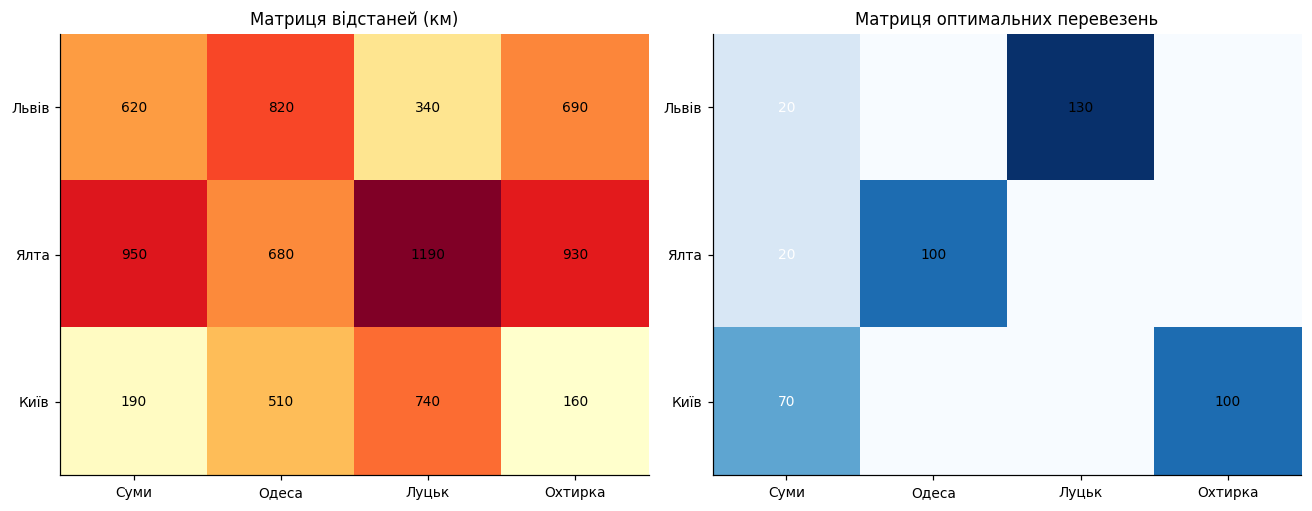

In [97]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(D, cmap='YlOrRd')
axes[0].set_title('Матриця відстаней (км)')
axes[0].set_xticks(range(len(споживачі)))
axes[0].set_xticklabels(споживачі, rotation=0)
axes[0].set_yticks(range(len(постачальники)))
axes[0].set_yticklabels(постачальники)

for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        axes[0].text(j, i, f'{D[i, j]:.0f}',
                     ha='center', va='center', color='black')

im2 = axes[1].imshow(X_scipy, cmap='Blues')
axes[1].set_title('Матриця оптимальних перевезень')
axes[1].set_xticks(range(len(споживачі)))
axes[1].set_xticklabels(споживачі, rotation=0)
axes[1].set_yticks(range(len(постачальники)))
axes[1].set_yticklabels(постачальники)

for i in range(X_scipy.shape[0]):
    for j in range(X_scipy.shape[1]):
        v = X_scipy[i, j]
        if v > 0:
            axes[1].text(j, i, f'{v:.0f}',
                         ha='center', va='center',
                         color='white' if v < 80 else 'black')

plt.tight_layout()
plt.show()


**Висновок: На теплових картах видно, що найвигідніші маршрути — це ті, де обсяги перевезень найбільші, а дорогі й довгі напрями майже не використовуються.** 

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [98]:
ІНСТРУМЕНТИ_ШІ = 'Cloud Code'    

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'ні',
    'етап 3, код на Python':                'синтаксис',
    'етапи 4–5, читання та перевірка звіту': 'ні',
    'етап 6, рішення про закупівлю':        'синтаксис',
    'етапи 7–8, перевірка та цілочисельність': 'синтаксис',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

ЩО_ПЕРЕВІРЕНО = 'формалізація (модель), логіка обмежень (ресурси), інтерпретація оптимуму (план), перевірка коду (Python), пояснення транспортної задачі (відмінність від виробничої)'

ПІДТВЕРДЖУЮ = True

In [99]:
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Лящук Соломія
інструменти:                               Cloud Code
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     синтаксис
етапи 4–5, читання та перевірка звіту:     ні
етап 6, рішення про закупівлю:             синтаксис
етапи 7–8, перевірка та цілочисельність:   синтаксис
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
формалізація (модель), логіка обмежень (ресурси), інтерпретація оптимуму (план), перевірка коду (Python), пояснення транспортної задачі (відмінність від виробничої)


---
# Крок 13. Фінальна самоперевірка

In [103]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
